
# Sales Prediction Using Machine Learning

## 1. Introduction

Sales prediction is a machine learning regression problem that estimates product sales based on advertising expenditure.

## 2. Objective

The objective is to predict sales using advertising budgets spent on:
- TV
- Radio
- Newspaper

## 3. Dataset Description

The Advertising dataset contains advertising expenditure values and corresponding sales figures.

## 4. Algorithms Used

- Linear Regression
- Random Forest Regression

## 5. Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_style("whitegrid")

print("Libraries imported successfully!")


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_style("whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load the dataset

df = pd.read_csv("Advertising.csv")

# Display first five records
display(df.head())

# Display dataset dimensions
print("Dataset Shape:", df.shape)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Dataset Shape: (200, 4)


In [3]:

# Dataset information

print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Statistical Summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000



Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Rows: 0


In [4]:

# Remove unnecessary index column if present

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values
print("Missing Values After Cleaning:")
print(df.isnull().sum())

# Final dataset shape
print("\nCleaned Dataset Shape:", df.shape)

# Display cleaned data
display(df.head())


Missing Values After Cleaning:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Cleaned Dataset Shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


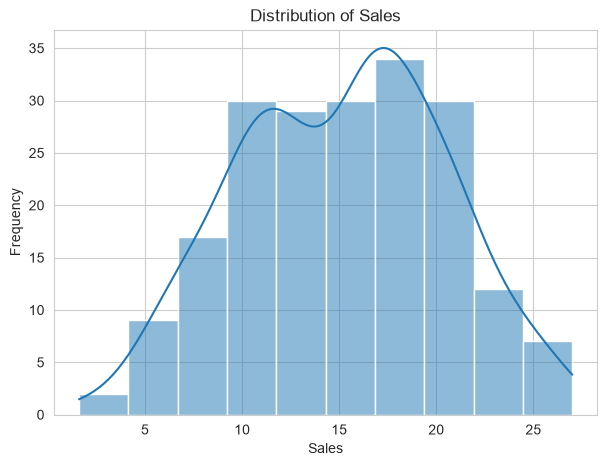

In [5]:

plt.figure(figsize=(7, 5))

sns.histplot(
    df["Sales"],
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()


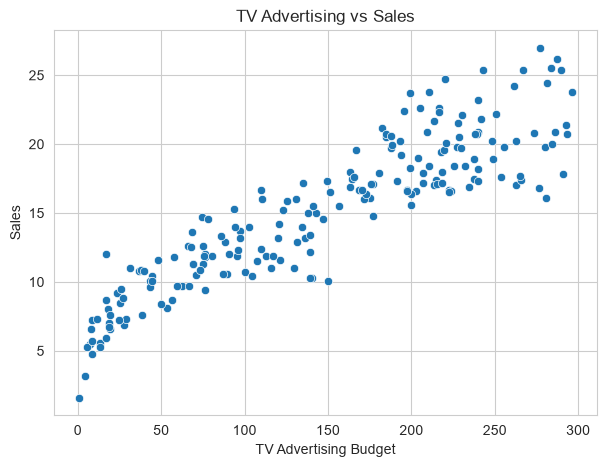

In [6]:

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="TV",
    y="Sales"
)

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Budget")
plt.ylabel("Sales")

plt.show()


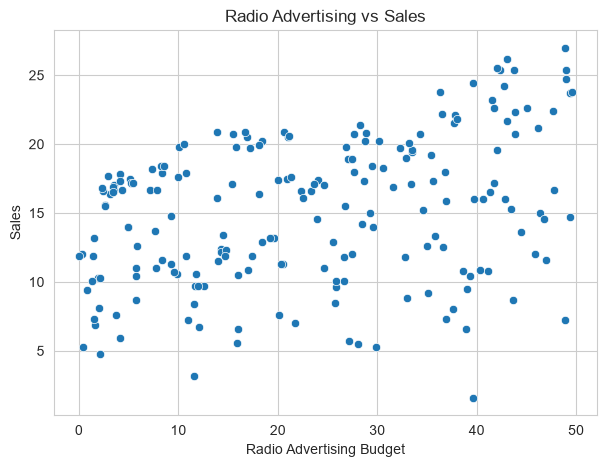

In [7]:

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Radio",
    y="Sales"
)

plt.title("Radio Advertising vs Sales")
plt.xlabel("Radio Advertising Budget")
plt.ylabel("Sales")

plt.show()


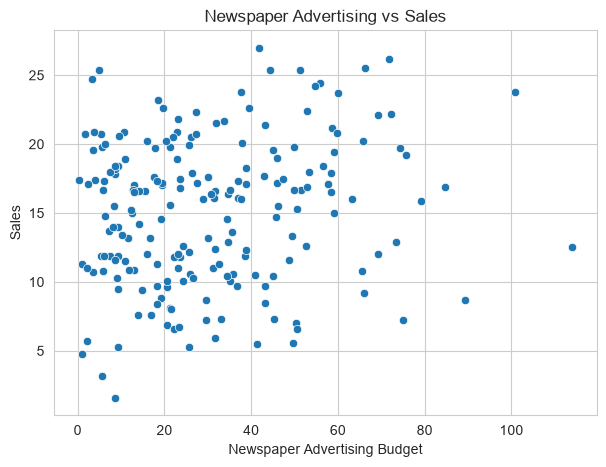

In [8]:

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Newspaper",
    y="Sales"
)

plt.title("Newspaper Advertising vs Sales")
plt.xlabel("Newspaper Advertising Budget")
plt.ylabel("Sales")

plt.show()


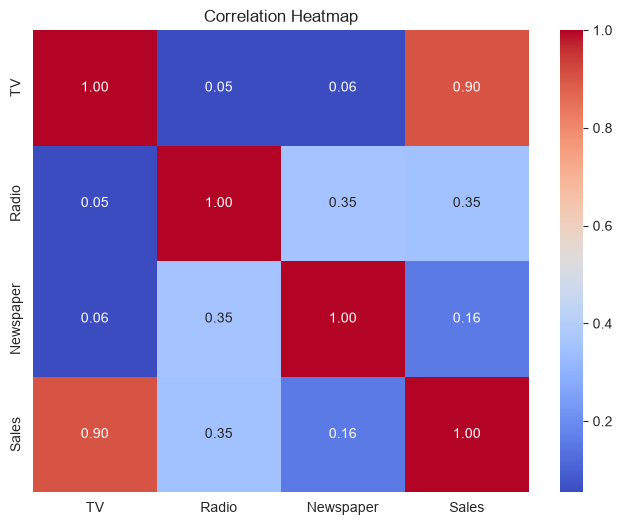

In [9]:

plt.figure(figsize=(8, 6))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


In [10]:
# Separate input features and target variable

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (160, 3)
Testing data shape: (40, 3)
Training target shape: (160,)
Testing target shape: (40,)


In [11]:
# Create and train Linear Regression model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Predict sales on test data

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")
print("\nFirst 10 predicted sales:")
print(linear_predictions[:10])

Linear Regression model trained successfully!

First 10 predicted sales:
[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475]


In [12]:
# Create and train Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict sales on test data

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("\nFirst 10 predicted sales:")
print(rf_predictions[:10])

Random Forest model trained successfully!

First 10 predicted sales:
[17.4155 22.425  19.8375  6.7945 22.962  13.602  22.6805  9.5935 16.88
 16.84  ]


In [13]:
# Function to evaluate regression models

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Compare both models

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.275,1.705,0.906
1,Random Forest,0.914,1.183,0.955


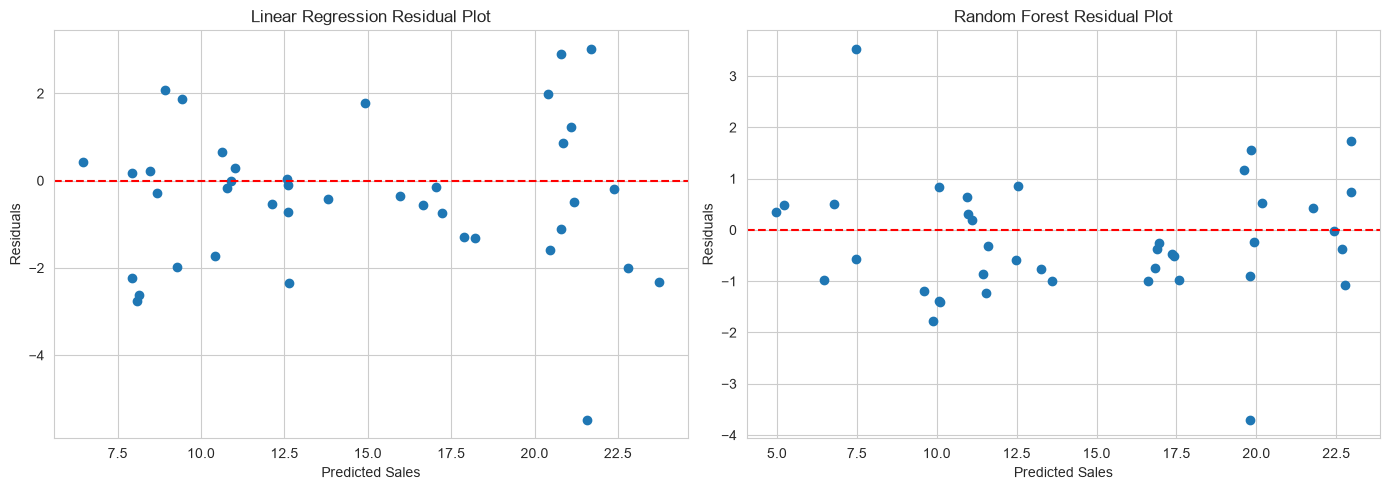

In [14]:
# Calculate residuals for both models

linear_residuals = y_test - linear_predictions
rf_residuals = y_test - rf_predictions

# Plot residuals

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(linear_predictions, linear_residuals)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_title("Linear Regression Residual Plot")
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residuals")

axes[1].scatter(rf_predictions, rf_residuals)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Random Forest Residual Plot")
axes[1].set_xlabel("Predicted Sales")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

,Feature,Importance
0,TV,0.844376
1,Radio,0.136431
2,Newspaper,0.019193


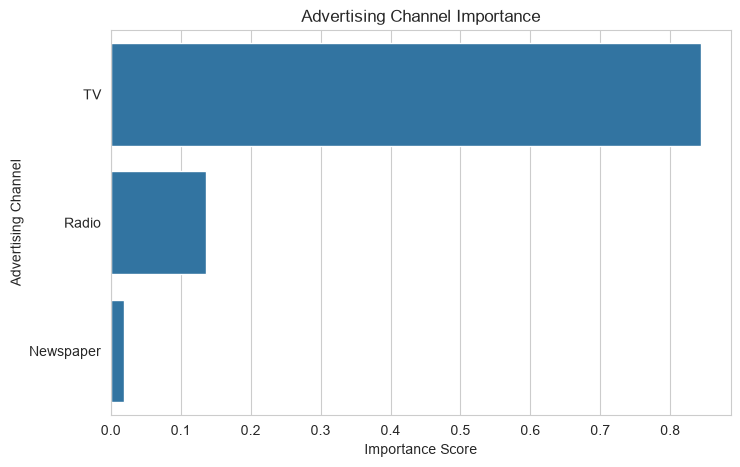

In [15]:
# Calculate feature importance

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

# Visualize feature importance

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Advertising Channel Importance")
plt.xlabel("Importance Score")
plt.ylabel("Advertising Channel")

plt.show()

## 13. Conclusion

In this project, machine learning techniques were used to predict product sales based on advertising expenditure across TV, Radio, and Newspaper channels.

The dataset was explored, cleaned, and analyzed using visualizations and correlation analysis. Two regression algorithms, Linear Regression and Random Forest Regression, were trained and evaluated.

The evaluation results showed that Random Forest Regression performed better than Linear Regression, achieving an MAE of 0.914, RMSE of 1.183, and R² score of 0.955.

Feature importance analysis revealed that TV advertising was the most influential predictor, followed by Radio and Newspaper advertising.

Therefore, Random Forest Regression was selected as the best-performing model for this dataset.

This project demonstrates how machine learning can help analyze advertising data and predict sales. The results provide insights into the predictive importance of different advertising channels.